<a href="https://colab.research.google.com/github/karkessler/dhbw-mathe3/blob/main/notebooks/numerik/04_gradient_descent_1d.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gradientenabstieg: Ein eindimensionales Beispiel

Dieses Notebook rechnet das Skriptbeispiel zum Gradientenabstiegsverfahren von Hand
durch, bevor die Mehrdimensionalität dazukommt (siehe `05_gradient_descent_rosenbrock.ipynb`
für den 2D-Fall).

Gegeben ist die Parabel

$$f(x) = x^2 - 2x + 3, \qquad f'(x) = 2x - 2$$

mit dem Startwert $x_0 = 4$ und der Schrittweite $\alpha = 0{,}25$. Die Update-Regel

$$x_{n+1} = x_n - \alpha \cdot f'(x_n) = x_n - 0{,}25 \cdot (2x_n - 2) = 0{,}5 \cdot x_n + 0{,}5$$

liefert die Folge $x_1 = 2{,}5,\ x_2 = 1{,}75,\ x_3 = 1{,}375,\ x_4 = 1{,}1875,\ x_5 = 1{,}09375,\ \dots$,
die gegen das Minimum $x^* = 1$ mit $f(x^*) = 2$ konvergiert.

In [1]:
def f(x):
    return x**2 - 2*x + 3


def f_strich(x):
    return 2*x - 2


alpha = 0.25
x = 4.0

print("Gradientenabstieg fuer f(x) = x^2 - 2x + 3, f'(x) = 2x - 2")
print(f"Startwert x0 = {x}, Schrittweite alpha = {alpha}\n")

for n in range(1, 6):
    x = x - alpha * f_strich(x)
    print(f"x_{n} = {x}")

print(f"\nKonvergenz gegen x* = 1 mit f(x*) = {f(1.0)}")

Gradientenabstieg fuer f(x) = x^2 - 2x + 3, f'(x) = 2x - 2
Startwert x0 = 4.0, Schrittweite alpha = 0.25

x_1 = 2.5
x_2 = 1.75
x_3 = 1.375
x_4 = 1.1875
x_5 = 1.09375

Konvergenz gegen x* = 1 mit f(x*) = 2.0


## Grafische Darstellung: Parabel, Iterationspunkte und Tangenten

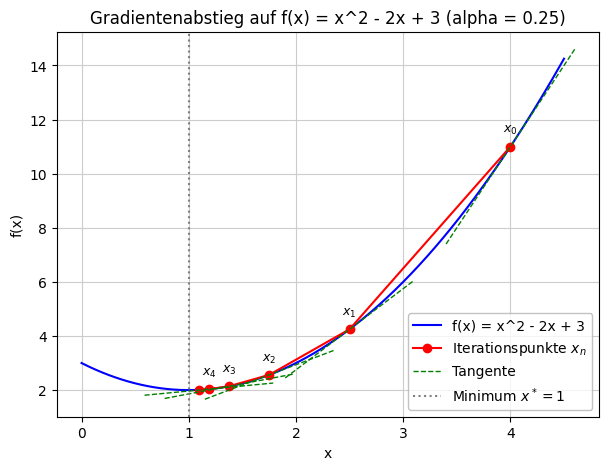

In [2]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'axes.edgecolor': 'black',
    'axes.labelcolor': 'black',
    'axes.titlecolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'text.color': 'black',
    'axes.grid': True,
    'grid.color': '0.8',
    'legend.facecolor': 'white',
    'legend.edgecolor': '0.7',
})

xs_iter = [4.0]
x = 4.0
for n in range(5):
    x = x - alpha * f_strich(x)
    xs_iter.append(x)

fig, ax = plt.subplots(figsize=(7, 5))

xs = np.linspace(0, 4.5, 300)
ax.plot(xs, f(xs), "b-", label="f(x) = x^2 - 2x + 3")

ax.plot(xs_iter, [f(xi) for xi in xs_iter], "ro-", markersize=6,
        label="Iterationspunkte $x_n$")

for i, xi in enumerate(xs_iter[:-1]):
    yi = f(xi)
    steigung = f_strich(xi)
    t = np.linspace(xi - 0.6, xi + 0.6, 2)
    ax.plot(t, yi + steigung * (t - xi), "g--", linewidth=1,
             label="Tangente" if i == 0 else None)
    ax.annotate(f"$x_{i}$", (xi, yi), textcoords="offset points",
                xytext=(0, 10), ha="center", fontsize=9)

ax.axvline(1.0, color="gray", linestyle=":", label="Minimum $x^*=1$")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.set_title(f"Gradientenabstieg auf f(x) = x^2 - 2x + 3 (alpha = {alpha})")
ax.legend()
plt.show()

## Einfluss der Schrittweite $\alpha$

In [3]:
print("Verhalten bei unterschiedlichen Schrittweiten alpha, Start x0 = 4\n")

for a, kommentar in [(0.1, "langsam"), (0.25, "wie im Skript"),
                     (0.9, "oszillierend"), (1.1, "divergent")]:
    x = 4.0
    folge = [x]
    for n in range(6):
        x = x - a * f_strich(x)
        folge.append(x)
    werte = ", ".join(f"{xi:.3f}" for xi in folge)
    print(f"alpha = {a:<4} ({kommentar:<15}): {werte}")

print("\nErklaerung ueber den Verstaerkungsfaktor je Schritt: (1 - 2*alpha)")
for a in [0.1, 0.25, 0.9, 1.1]:
    faktor = 1 - 2 * a
    print(f"  alpha = {a:<4} -> Faktor (1-2*alpha) = {faktor:+.2f}  "
          f"(|Faktor| {'< 1: konvergiert' if abs(faktor) < 1 else '>= 1: divergiert'})")

Verhalten bei unterschiedlichen Schrittweiten alpha, Start x0 = 4

alpha = 0.1  (langsam        ): 4.000, 3.400, 2.920, 2.536, 2.229, 1.983, 1.786
alpha = 0.25 (wie im Skript  ): 4.000, 2.500, 1.750, 1.375, 1.188, 1.094, 1.047
alpha = 0.9  (oszillierend   ): 4.000, -1.400, 2.920, -0.536, 2.229, 0.017, 1.786
alpha = 1.1  (divergent      ): 4.000, -2.600, 5.320, -4.184, 7.221, -6.465, 9.958

Erklaerung ueber den Verstaerkungsfaktor je Schritt: (1 - 2*alpha)
  alpha = 0.1  -> Faktor (1-2*alpha) = +0.80  (|Faktor| < 1: konvergiert)
  alpha = 0.25 -> Faktor (1-2*alpha) = +0.50  (|Faktor| < 1: konvergiert)
  alpha = 0.9  -> Faktor (1-2*alpha) = -0.80  (|Faktor| < 1: konvergiert)
  alpha = 1.1  -> Faktor (1-2*alpha) = -1.20  (|Faktor| >= 1: divergiert)
